[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/pandas%E7%9A%84%E5%9F%BA%E7%A4%8E%E5%8A%9F%E8%83%BD/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E7%A5%A8%E6%88%BF%E6%8E%92%E8%A1%8C%E6%A6%9C%E8%88%87%E7%88%86%E7%B4%85%E7%9A%84%E7%A7%98%E5%AF%86.ipynb)

# 🏆 票房排行榜與爆紅的秘密：排序、排名、分級與相關係數

> 🎯 **情境**：上一章你做出了第一份票房報表。這次電影公司的行銷經理來問你三個問題：「**每一年的冠軍是誰？**」「**一部電影的票房『通常』有多少——平均數可以相信嗎？**」「**上映的戲院越多，票房就越高嗎？**」用 pandas 的排序、排名、分級與統計功能，一次回答。

| 素材檔案 | 內容 |
| --- | --- |
| `全國電影票房_2016至今.json` | 文化部全國電影票房：2016 年至今 7,000 多部電影的國別、上映日、戲院數、票數與票房金額（JSON） |

| 📡 資料來源（政府資料開放平台） | 提供機關 | 下載日期 |
| --- | --- | --- |
| [全國電影票房統計數據](https://data.gov.tw/dataset/94224) | 文化部 | 2026-10-24 |

> ✅ 這些都是**真實的政府開放資料**，依「政府資料開放授權條款－第1版」使用。課堂上統一使用上表日期的快照，所以每個人跑出來的數字都一樣。

## 🗺️ 今日任務地圖

| 關卡 | 要回答的問題 |
| --- | --- |
| ⬜ 任務 1 | 讀取並整理（複習上一章） |
| ⬜ 任務 2 | 用條件找電影——`query` 和 `loc` |
| ⬜ 任務 3 | 每一年的冠軍是誰？——排序 |
| ⬜ 任務 4 | 「小兵立大功」——排名看出誰最有粉絲 |
| ⬜ 任務 5 | 替每部電影分級——`apply` |
| ⬜ 任務 6 | 平均數會騙人！——`describe` 一次看懂分布 |
| ⬜ 任務 7 | 上映戲院越多，票房就越高嗎？——相關係數 |

**怎麼用這本 Notebook**：從上到下按 `Shift + Enter` 一格一格執行。每個任務都會先講「你想知道什麼」，再給程式，最後用 💡 **看懂結果** 告訴你這個數字代表什麼。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '全國電影票房_2016至今.json',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/pandas%E7%9A%84%E5%9F%BA%E7%A4%8E%E5%8A%9F%E8%83%BD/pandas%E7%9A%84%E5%9F%BA%E7%A4%8E%E5%8A%9F%E8%83%BD_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['全國電影票房_2016至今.json']


In [ ]:
# --- 設定 Matplotlib 中文字型支援（Mac / Windows / Colab 通用）---
%pip install -q mplfonts

import glob, os
import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)   # 直接註冊 mplfonts 內附的字型，不改任何檔案
use_font("Noto Sans CJK SC")              # 套用思源黑體，負號也會一起處理

## 任務 1：讀取並整理（複習上一章）

**白話說明**：和上一章一樣：JSON → DataFrame，刪掉沒用的欄位、改中文欄名、去掉票房是 -1 的電影，再新增「年」和「票房(萬)」。

In [3]:
import json
import pandas as pd

with open('全國電影票房_2016至今.json', encoding='utf-8-sig') as f:
    movies = pd.DataFrame(json.load(f)['List'])

movies = (movies.rename(columns={'Country': '國別', 'Name': '片名', 'ReleaseDate': '上映日',
                                 'TheaterCount': '戲院數', 'TotalTickets': '票數', 'TotalAmounts': '票房'})
                [['片名', '國別', '上映日', '戲院數', '票數', '票房']])
movies = movies[movies['票房'] > 0].copy()                            # 去掉 -1（沒有資料）
movies['年'] = movies['上映日'].str[:4].astype(int)
movies['票房(萬)'] = (movies['票房'] / 1e4).round(0)
movies.head()

,片名,國別,上映日,戲院數,票數,票房,年,票房(萬)
0,《我在學校旅行中被分到了一個糟糕的小組》高校同學會－大銀幕限定青春重映,日本,2026-10-11T00:00:00,1,94,122200.0,2026,12.0
1,YORUSHIKA LIVE「盜作」,日本,2026-10-09T00:00:00,11,15023,7394950.0,2026,739.0
2,金劫任務,美國,2026-10-08T00:00:00,72,17535,4353605.0,2026,435.0
3,鬼入室,越南,2026-10-08T00:00:00,44,2664,695375.0,2026,70.0
4,驚天劫機,越南,2026-10-08T00:00:00,30,4827,1275241.0,2026,128.0


## 任務 2：用條件找電影——`query` 和 `loc`

**白話說明**：`query('條件')` 用接近口語的方式寫篩選條件；`loc[列條件, 欄位]` 可以同時挑「哪些列」和「哪些欄」。`str.contains('鬼滅')` 找片名裡有「鬼滅」的電影。

In [4]:
display(movies.query('年 == 2025 and 國別 == "韓國"').nlargest(3, '票房'))          # 2025 年最賣座的 3 部韓國片
display(movies.loc[movies['片名'].str.contains('鬼滅'), ['片名', '年', '戲院數', '票房(萬)']])   # 所有「鬼滅」系列

,片名,國別,上映日,戲院數,票數,票房,年,票房(萬)
811,全知讀者視角,韓國,2025-07-21T00:00:00,99,286397,78508397.0,2025,7851.0
642,G-DRAGON IN CINEMA [Übermensch],韓國,2025-10-28T00:00:00,47,55071,38475084.0,2025,3848.0
1141,(G)I-DLE WORLD TOUR [iDOL] IN CINEMAS,韓國,2025-01-29T00:00:00,26,40949,25683290.0,2025,2568.0


,片名,年,戲院數,票房(萬)
788,劇場版「鬼滅之刃」無限城篇 第一章 猗窩座再襲,2025,100,85655.0
1722,「鬼滅之刃」 絆之奇蹟，邁向柱訓練,2024,94,4897.0
2415,「鬼滅之刃」上弦集結，前進刀匠村,2023,91,6658.0
3822,劇場版「鬼滅之刃」無限列車篇,2020,102,63634.0


## 任務 3：每一年的冠軍是誰？——排序

**白話說明**：`sort_values` 可以同時依好幾個欄位排序：先依「年」由小到大，同一年再依「票房」由大到小；這時每一年的第一名就排在最前面，`drop_duplicates('年')` 只留每年的第一筆。

In [5]:
champions = (movies[movies['年'] >= 2016]
             .sort_values(['年', '票房'], ascending=[True, False])
             .drop_duplicates('年'))
champions[['年', '片名', '國別', '票房(萬)']]

,年,片名,國別,票房(萬)
6841,2016,屍速列車,韓國,37692.0
6417,2017,玩命關頭8,美國,65084.0
5680,2018,復仇者聯盟：無限之戰,美國,64178.0
4914,2019,復仇者聯盟:終局之戰,美國,91046.0
3822,2020,劇場版「鬼滅之刃」無限列車篇,日本,63634.0
3160,2021,蜘蛛人：無家日,美國,49822.0
2521,2022,阿凡達：水之道,美國,75031.0
2165,2023,不可能的任務：致命清算 第一章,美國,43671.0
1551,2024,腦筋急轉彎2,美國,51361.0
788,2025,劇場版「鬼滅之刃」無限城篇 第一章 猗窩座再襲,日本,85655.0


> 💡 **看懂結果**：11 個年度冠軍裡，美國片拿了 8 次、日本片 2 次（都是鬼滅之刃！）、韓國片 1 次（2016 年的《屍速列車》）。
> 2020 年疫情讓好萊塢大片延期，日本動畫《鬼滅之刃 無限列車篇》趁勢拿下冠軍；2025 年鬼滅再度封王。

## 任務 4：「小兵立大功」——排名看出誰最有粉絲

**白話說明**：`rank(ascending=False)` 算出名次（最大的是第 1 名）。我們幫 2025 年的電影算兩種名次：**票房名次**和**戲院數名次**。如果一部電影只在很少戲院上映，票房名次卻很前面，代表它的觀眾「**很死忠**」。

In [6]:
y2025 = movies[movies['年'] == 2025].copy()
y2025['票房名次'] = y2025['票房'].rank(ascending=False, method='min').astype(int)
y2025['戲院名次'] = y2025['戲院數'].rank(ascending=False, method='min').astype(int)
y2025['名次進步'] = y2025['戲院名次'] - y2025['票房名次']             # 數字越大，越「以小搏大」

y2025.sort_values('名次進步', ascending=False).head(6)[['片名', '國別', '戲院數', '票房(萬)', '戲院名次', '票房名次', '名次進步']]

,片名,國別,戲院數,票房(萬),戲院名次,票房名次,名次進步
840,Yorushika LIVE 2024「前世」,日本,10,562.0,539,133,406
580,劇場版 BanG Dream! It's MyGO!!!!! 前篇：春暖向陽，迷星之貓,日本,12,601.0,504,126,378
710,熱烈,中國大陸,7,251.0,568,199,369
898,膽大黨：邪視,日本,17,1988.0,416,56,360
553,劇場版 BanG Dream! It's MyGO!!!!! 後篇：唱吧、成為我們羈絆的詩歌...,日本,12,482.0,504,148,356
1111,"劇場版 YOASOBI 5th ANNIVERSARY DOME LIVE 2024 ""超現實""",日本,17,1552.0,416,63,353


> 💡 **看懂結果**：以小搏大的冠軍是 **Yorushika 演唱會電影、《BanG Dream! It's MyGO!!!!!》劇場版**這類作品——只在 10 幾家戲院上映，票房名次卻衝進前 150。它們的觀眾是「**為了偶像／動畫一定要去看**」的鐵粉。
> 這就是「**利基市場**」：不用大規模上映，只要找對觀眾。

## 任務 5：替每部電影分級——`apply`

**白話說明**：寫一個函式，輸入票房、回傳等級；`apply` 會把這個函式**套用到每一格**。

In [7]:
def grade(amount):
    if amount >= 5e8:
        return '🔥 現象級（5 億以上）'
    elif amount >= 1e8:
        return '賣座（1～5 億）'
    elif amount >= 1e7:
        return '普通（1,000 萬～1 億）'
    return '小眾（1,000 萬以下）'

movies['等級'] = movies['票房'].apply(grade)
movies['等級'].value_counts()

等級
小眾（1,000 萬以下）      6345
普通（1,000 萬～1 億）     764
賣座（1～5 億）           199
🔥 現象級（5 億以上）         14
Name: count, dtype: int64

> 💡 **看懂結果**：7,300 多部電影裡，**破 5 億的只有 14 部**，而將近 87% 的電影票房不到 1,000 萬。電影是一個「**少數贏家拿走大部分**」的產業。

## 任務 6：平均數會騙人！——`describe` 一次看懂分布

**你想知道**：「一部電影的票房『通常』是多少？」

In [8]:
movies['票房(萬)'].describe().round(0)

count     7322.0
mean      1129.0
std       4873.0
min          0.0
25%         12.0
50%         50.0
75%        279.0
max      91046.0
Name: 票房(萬), dtype: float64

> 😱 **平均數（mean）是 1,129 萬，中位數（50%）卻只有 50 萬——差了 22 倍！**
>
> 因為少數幾部 5 億、9 億的大片，把平均數往上拉得很高。這時候**中位數**才代表「一般電影」的票房：一半的電影賣不到 50 萬。
> 以後看到「平均薪資」、「平均房價」的新聞，記得多問一句：**中位數是多少？**

## 任務 7：上映戲院越多，票房就越高嗎？——相關係數

**白話說明**：相關係數介於 -1 到 1：越接近 1，代表「一個變大、另一個也跟著變大」越明顯。`corr()` 預設是 Pearson（看直線關係）；`method='spearman'` 看的是「**名次**」的關係，比較不怕極端值。

Pearson 相關係數： 0.47


Spearman 相關係數（用名次算）： 0.88


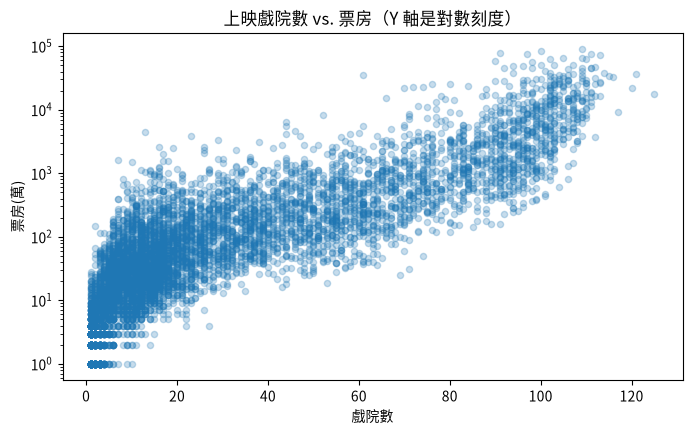

In [9]:
import matplotlib.pyplot as plt

print('Pearson 相關係數：', round(movies['戲院數'].corr(movies['票房']), 2))
print('Spearman 相關係數（用名次算）：', round(movies['戲院數'].corr(movies['票房'], method='spearman'), 2))

ax = movies.plot.scatter(x='戲院數', y='票房(萬)', alpha=0.25, figsize=(8, 4.5), logy=True,
                         title='上映戲院數 vs. 票房（Y 軸是對數刻度）')
plt.show()

> 💡 **看懂結果**：Spearman 高達 **0.88**——戲院越多，票房「名次」通常越前面，關係非常強；Pearson 只有 0.47，是被少數超級大片的極端值拉低了。
>
> ⚠️ **但是，相關不等於因果！** 是「戲院多 → 票房高」，還是「片商預期會賣 → 才排很多戲院」？資料只能告訴你兩者一起變化，**不能告訴你誰造成誰**。
>
> 🤖 **換你問 AI**：「請計算 DataFrame 中『戲院數』與『票房』的 Pearson 和 Spearman 相關係數，解釋兩者為什麼差很多，並提醒我相關與因果的差別。」

---

## ✍️ 換你動手：練習區

每一題都有三格：**① 半成品程式**（把 `___` 換成正確的程式）→ **② ✅ 檢查格**（自動告訴你對不對）→ **③ 🔑 參考解答**（折疊起來，先自己試）。

> 看到 `NameError: name '___' is not defined` 不用緊張，那代表還有空格沒填。

In [10]:
# @title 🧰 練習檢查小幫手（執行一次就好，不用看懂裡面的程式）
import math
import numpy as np
import pandas as pd


def _same(ans, expected, ordered=False):
    if isinstance(expected, (pd.DataFrame, pd.Series)):
        if type(ans) is not type(expected):
            return False
        try:
            assert_equal = pd.testing.assert_frame_equal if isinstance(expected, pd.DataFrame) else pd.testing.assert_series_equal
            if not ordered:
                ans, expected = ans.sort_index(), expected.sort_index()
            assert_equal(ans, expected, check_names=False, check_dtype=False,
                         check_index_type=False, check_exact=False, rtol=1e-3, atol=0.06,
                         **({'check_column_type': False} if isinstance(expected, pd.DataFrame) else {}))
            return True
        except (AssertionError, TypeError, ValueError):
            return False
    if isinstance(expected, np.ndarray):
        return np.asarray(ans).shape == expected.shape and np.allclose(np.asarray(ans, dtype=float), expected, atol=0.06)
    if isinstance(expected, (int, float, np.number)) and not isinstance(expected, bool):
        try:
            return math.isclose(float(ans), float(expected), rel_tol=1e-3, abs_tol=0.06)
        except (TypeError, ValueError):
            return False
    if isinstance(expected, (list, tuple, set)):
        return list(ans) == list(expected) if not isinstance(expected, set) else set(ans) == expected
    return ans == expected


def check(name, expected, ordered=False):
    """比對學生的變數 name 和正確答案 expected，印出 ✅ 或 ❌；ordered=True 時連排列順序也要一樣。"""
    if name not in globals():
        print(f'⏳ 還找不到變數 {name}：請先把上一格的 ___ 填好並執行')
        return
    ans = globals()[name]
    if _same(ans, expected, ordered):
        print(f'✅ {name} 答對了！')
        return
    print(f'❌ {name} 還不對，再檢查看看：')
    if type(ans) is not type(expected):
        print(f'   型態不同：你的是 {type(ans).__name__}，應該是 {type(expected).__name__}')
    elif hasattr(expected, 'shape') and getattr(ans, 'shape', None) != expected.shape:
        print(f'   大小不同：你的是 {ans.shape}，應該是 {expected.shape}')
    else:
        print('   型態和大小都對了，是數值' + ('或排列順序' if ordered else '') + '不一樣——檢查一下篩選條件或計算方式')


print('🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格')

🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格


### ✍️ 練習 1：2024 年最賣座的韓國電影是哪一部？

<details><summary>💡 卡住了？點我看提示</summary>

`query('年 == 2024 and 國別 == "韓國"')` 篩出 2024 年的韓國片，再用 `nlargest(1, '票房')` 或 `sort_values` 找第一名。

</details>

In [ ]:
# ✏️ 練習 1：把 ___ 換成正確的程式，再按執行
korea = movies.query('年 == ___ and 國別 == "韓國"')
korea_top = korea.nlargest(1, '票房')['片名'].iloc[0]
print('2024 年最賣座的韓國片：', korea_top)

In [ ]:
# @title ✅ 執行這格，檢查練習 1
check('korea_top', movies.query('年 == 2024 and 國別 == "韓國"').nlargest(1, '票房')['片名'].iloc[0])

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
korea = movies.query('年 == 2024 and 國別 == "韓國"')
korea_top = korea.nlargest(1, '票房')['片名'].iloc[0]
print('2024 年最賣座的韓國片：', korea_top)
```

</details>

### ✍️ 練習 2：2025 年的電影，票房的平均數和中位數各是多少萬？

<details><summary>💡 卡住了？點我看提示</summary>

先篩出 2025 年，再對「票房(萬)」用 `.mean()` 和 `.median()`。

</details>

In [ ]:
# ✏️ 練習 2：把 ___ 換成正確的程式，再按執行
movies_2025 = movies[movies['年'] == ___]
avg_2025 = movies_2025['票房(萬)'].mean()
median_2025 = movies_2025['票房(萬)'].___()
print(f'2025 年：平均 {avg_2025:,.0f} 萬，中位數 {median_2025:,.0f} 萬')

In [ ]:
# @title ✅ 執行這格，檢查練習 2
check('avg_2025', movies.loc[movies['年'] == 2025, '票房(萬)'].mean())
check('median_2025', movies.loc[movies['年'] == 2025, '票房(萬)'].median())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
movies_2025 = movies[movies['年'] == 2025]
avg_2025 = movies_2025['票房(萬)'].mean()
median_2025 = movies_2025['票房(萬)'].median()
print(f'2025 年：平均 {avg_2025:,.0f} 萬，中位數 {median_2025:,.0f} 萬')
```

</details>

### ✍️ 練習 3：每一年的「國片冠軍」是哪一部？

<details><summary>💡 卡住了？點我看提示</summary>

先篩出國片（國別是 `'中華民國'`）而且 2016 年以後，接著用任務 3 的招式：依年、票房排序後 `drop_duplicates('年')`。

</details>

In [ ]:
# ✏️ 練習 3：把 ___ 換成正確的程式，再按執行
tw_champions = (movies[(movies['國別'] == ___) & (movies['年'] >= 2016)]
                .sort_values(['年', '票房'], ascending=[True, ___])
                .drop_duplicates(___))
tw_champions[['年', '片名', '票房(萬)']]

In [ ]:
# @title ✅ 執行這格，檢查練習 3
check('tw_champions', movies[(movies['國別'] == '中華民國') & (movies['年'] >= 2016)]
                      .sort_values(['年', '票房'], ascending=[True, False]).drop_duplicates('年'))

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
tw_champions = (movies[(movies['國別'] == '中華民國') & (movies['年'] >= 2016)]
                .sort_values(['年', '票房'], ascending=[True, False])
                .drop_duplicates('年'))
tw_champions[['年', '片名', '票房(萬)']]
```

</details>

---

## 🏆 任務完成！今天你用程式做到了這些事

- ✅ 任務 1：讀取並整理（複習上一章）
- ✅ 任務 2：用條件找電影——`query` 和 `loc`
- ✅ 任務 3：每一年的冠軍是誰？——排序
- ✅ 任務 4：「小兵立大功」——排名看出誰最有粉絲
- ✅ 任務 5：替每部電影分級——`apply`
- ✅ 任務 6：平均數會騙人！——`describe` 一次看懂分布
- ✅ 任務 7：上映戲院越多，票房就越高嗎？——相關係數

> 🎯 **帶走一句話**：程式只是工具，真正有價值的是你從資料裡找到的那句「所以我們應該……」。
> 把上面每個 💡 **看懂結果** 用自己的話寫成一句建議，就是一份可以拿去報告的分析。